# B-8802B · modelo atual × modelo sem temperatura, lado a lado

Em todas as figuras: **à esquerda o modelo atual** (em produção, 5 sensores com a temperatura do mancal LA) e **à
direita o modelo sem temperatura** (vibrações LA/LNA + pressões de sucção e descarga), na mesma escala.

- **Linha de cima:** o sensor, com os **pontos vermelhos** onde o modelo está em alerta (a regra de produção: 15 de 20
  leituras acima do limiar e duração ≥ 1 h).
- **Linha de baixo:** o score do modelo dividido pelo limiar (acima de 1 = acima do limiar).

O modelo sem temperatura é um dos 12 do retreino completo (mesma arquitetura do atual: VAE 128-64-32, latente 16, taxa
1e-4), com a mesma janela de treino (2025) e a mesma regra de alarme.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from transpetro_modelos.drift import battery
B = battery.BATTERY["B-8802B-2025"]; si = battery.si
raw = si.carregar_dados(B["data_new"])
raw22 = si.carregar_dados(next(Path(B["cross_era"]["csv"]).rglob(B["cross_era"]["csv_glob"])))
FALHA = pd.Timestamp(B["cross_era"]["failure"])
MODELOS = {"modelo atual (com temperatura)": (Path(B["bundle"]), "#2a78d6"),
           "modelo sem temperatura": (RAIZ / "results/vp_vs_nivel/bundles/vp/l128-64-32_lat16_lr0.0001_s1", "#1baf7a")}
VERMELHO, SERIE, TEXTO = "#e5484d", "#6f9fd1", "#52514e"
plt.rcParams.update({"font.size": 10.5})
def estilo(ax, t=None, size=11):
    if t: ax.set_title(t, loc="left", fontsize=size, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)

def rodar(bundle, df):
    torch.manual_seed(0)
    r = battery.score(bundle, df)
    thr = json.loads((bundle / "alarm.json").read_text())["threshold"]
    return r["reconstruction_error"] / thr, r["is_anomaly"].astype(bool)

def episodios(f):
    x = f[f]
    if x.empty: return []
    g = x.index.to_series().diff().gt(pd.Timedelta("1h")).cumsum()
    return [e.index[0] for _, e in x.groupby(g)]

def lado_a_lado(df, ini, fim, sensor, un, titulo, agreg=None, marcas=(), ylim_score=None):
    """Uma coluna por modelo: sensor com os alertas em cima, score ÷ limiar embaixo."""
    w = df.loc[pd.Timestamp(ini) - pd.Timedelta(days=2):fim]
    v = w[sensor].where(w["Pressão Descarga"] > 35).loc[ini:fim]
    fig, axes = plt.subplots(2, 2, figsize=(16, 6.2), sharex=True, sharey="row", gridspec_kw={"height_ratios": [1.5, 1]})
    resumo = {}
    for j, (nome, (b, cor)) in enumerate(MODELOS.items()):
        s, a = rodar(b, w); s, a = s.loc[ini:fim], a.loc[ini:fim]
        vv = v.resample(agreg).median() if agreg else v
        axes[0, j].plot(vv.index, vv.values, color=SERIE, lw=0.7)
        p = v.reindex(a.index)[a]; axes[0, j].scatter(p.index, p.values, color=VERMELHO, s=7, zorder=3)
        ss = s.resample(agreg).median() if agreg else s.groupby(s.index.to_series().diff().gt(pd.Timedelta("10min")).cumsum().values).transform(lambda x: x.rolling(12, min_periods=1).median())
        axes[1, j].plot(ss.index, ss.values, color=cor, lw=1.2); axes[1, j].axhline(1, color="black", ls="--", lw=1)
        ep = episodios(a)
        txt = f"{len(ep)} episódio(s) de alerta" + (": " + ", ".join(f"{t:%d/%m}" for t in ep[:6]) + ("…" if len(ep) > 6 else "") if ep else "")
        estilo(axes[0, j], f"{nome}\n{txt}")
        axes[1, j].set_ylabel("score ÷ limiar" if j == 0 else ""); axes[0, j].set_ylabel(un if j == 0 else "")
        for t, rot in marcas:
            for ax in axes[:, j]: ax.axvline(pd.Timestamp(t), color="#f0a020", ls="--", lw=1.3)
            axes[0, j].text(pd.Timestamp(t), 1.0, f" {rot}", transform=axes[0, j].get_xaxis_transform(), fontsize=9.5, color="#b5741a", va="top")
        resumo[nome] = (a, ep)
        estilo(axes[1, j])
    if ylim_score: axes[1, 0].set_ylim(*ylim_score)
    for ax in axes[1]: ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y" if (pd.Timestamp(fim) - pd.Timestamp(ini)).days > 60 else "%d/%m"))
    fig.suptitle(f"B-8802B · {titulo}", x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(); plt.show()
    return resumo

## 1. 2025 a ago/2026 inteiro

Vibração do mancal LA (mediana de 6 h) e score (mediana de 6 h). É aqui que aparece a diferença de comportamento com o
mancal mais frio em abr–ago/2026.

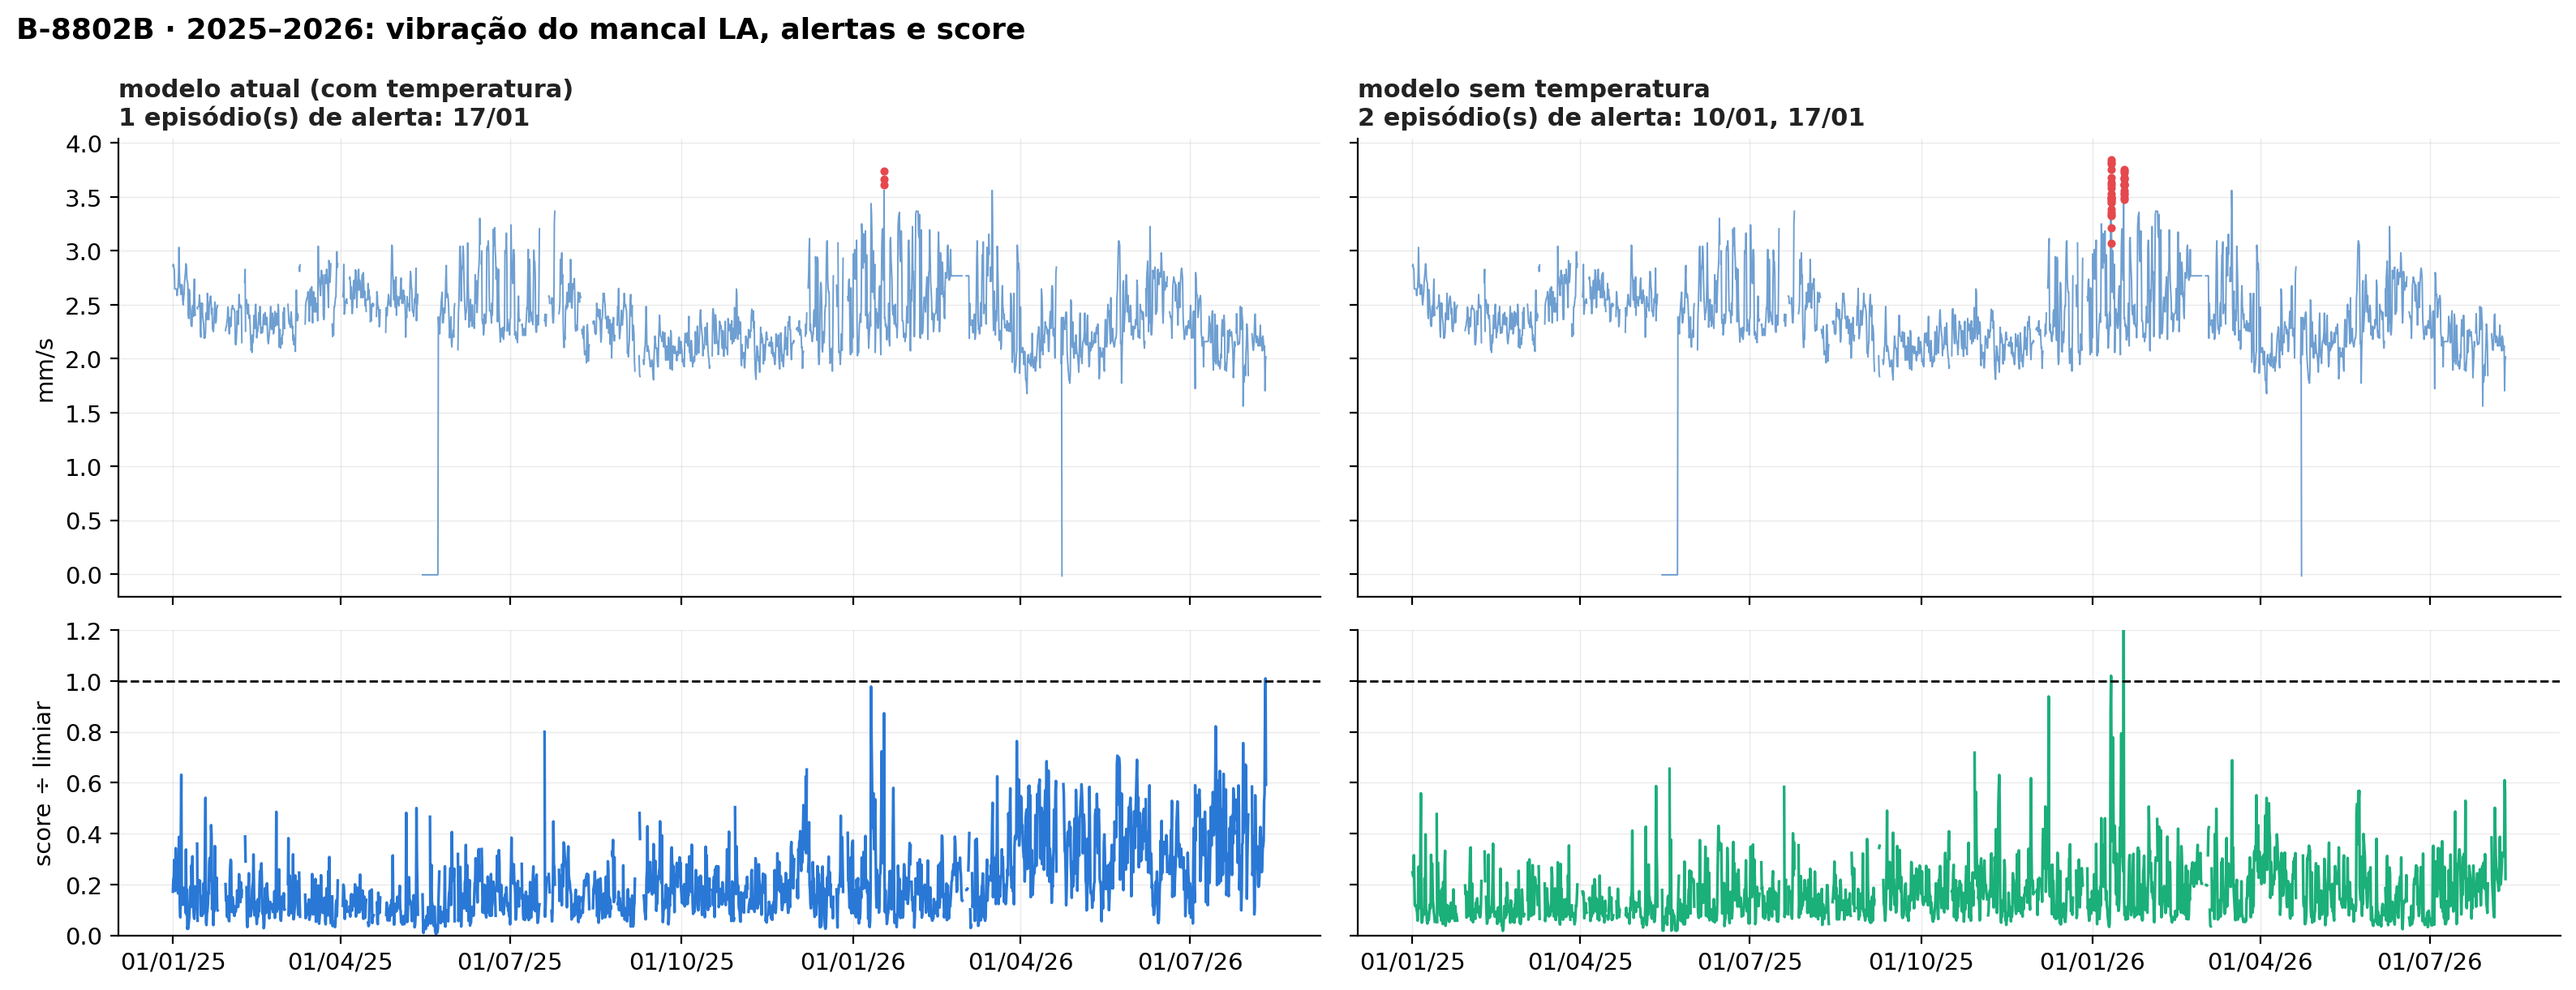

In [2]:
r_tudo = lado_a_lado(raw, "2025-01-01", "2026-08-11", "Vibração Bomba LA", "mm/s", "2025–2026: vibração do mancal LA, alertas e score",
                     agreg="6h", ylim_score=(0, 1.2))

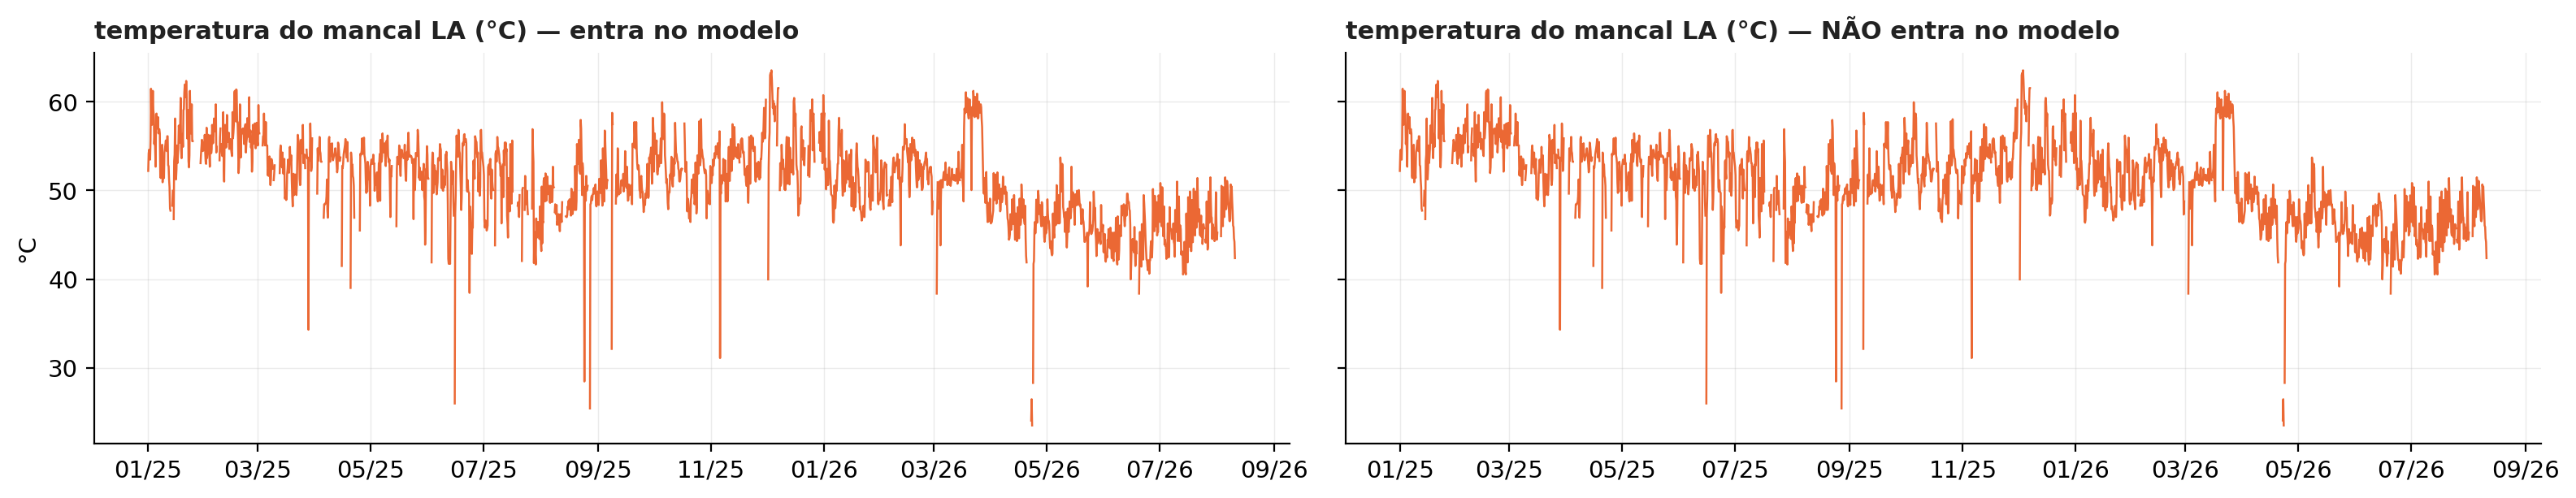

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3.2), sharey=True)
t = raw["Temperatura Bomba LA"].where(raw["Pressão Descarga"] > 35).resample("6h").median()
for ax, (nome, (b, cor)) in zip(axes, MODELOS.items()):
    ax.plot(t.index, t.values, color="#eb6834", lw=0.9)
    entra = "entra no modelo" if "atual" in nome else "NÃO entra no modelo"
    estilo(ax, f"temperatura do mancal LA (°C) — {entra}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
axes[0].set_ylabel("°C"); fig.tight_layout()

In [4]:
linhas = []
for nome, (b, cor) in MODELOS.items():
    s, a = rodar(b, raw)
    e25 = s.loc["2025"].mean()
    linhas.append({"modelo": nome, "score médio abr–ago/26 ÷ 2025": round(s.loc["2026-04":"2026-08"].mean() / e25, 2),
                   "% do tempo em alerta 2025": round(100 * a.loc["2025"].mean(), 3),
                   "% do tempo em alerta 2026": round(100 * a.loc["2026"].mean(), 3),
                   "episódios 2026": len(episodios(a.loc["2026"]))})
pd.DataFrame(linhas).set_index("modelo")

,score médio abr–ago/26 ÷ 2025,% do tempo em alerta 2025,% do tempo em alerta 2026,episódios 2026
modelo,,,,
modelo atual (com temperatura),2.12,0.0,0.005,1
modelo sem temperatura,1.24,0.0,0.064,2


**Leitura:** com o mancal esfriando (temperatura caindo de ~55 para ~45 °C a partir de abril/2026), o score do modelo
atual sobe (fica mais perto do limiar, sem alertar); o do modelo sem temperatura não muda. Os dois só alertam em janeiro/2026.

## 2. Janeiro de 2026: os dois episódios de vibração

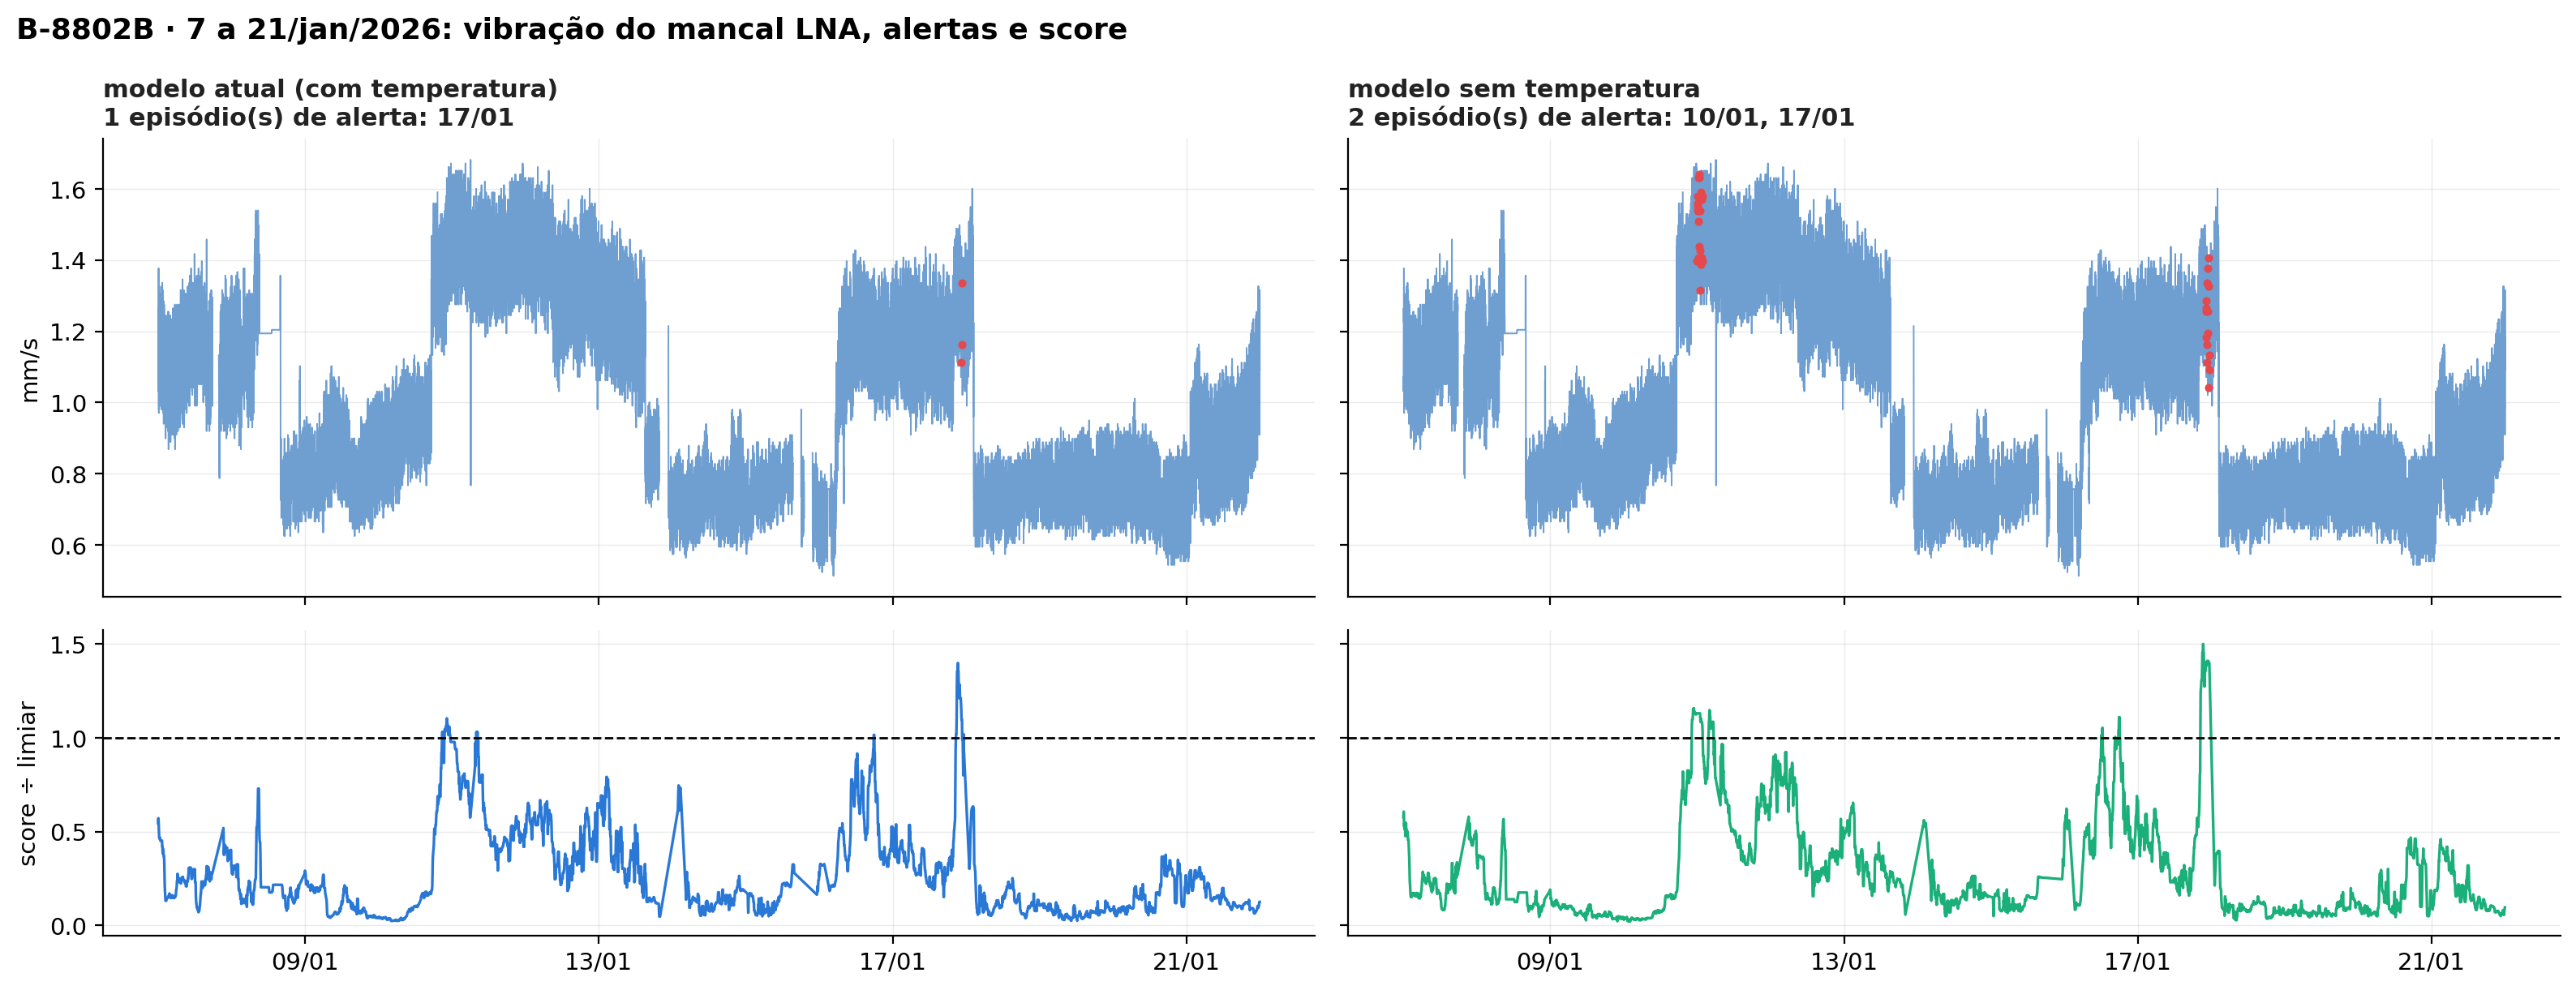

In [5]:
_ = lado_a_lado(raw, "2026-01-07", "2026-01-21", "Vibração Bomba LNA", "mm/s", "7 a 21/jan/2026: vibração do mancal LNA, alertas e score")

Nos dois episódios (10–12/01 e 17/01) a vibração fica acima do normal de 2025 — no de 10–12/01 a LNA vai ainda mais
alto que no de 17/01. O modelo sem temperatura alerta nos dois; o atual, só no de 17/01.

## 3. Abril a agosto de 2026: o mancal mais frio

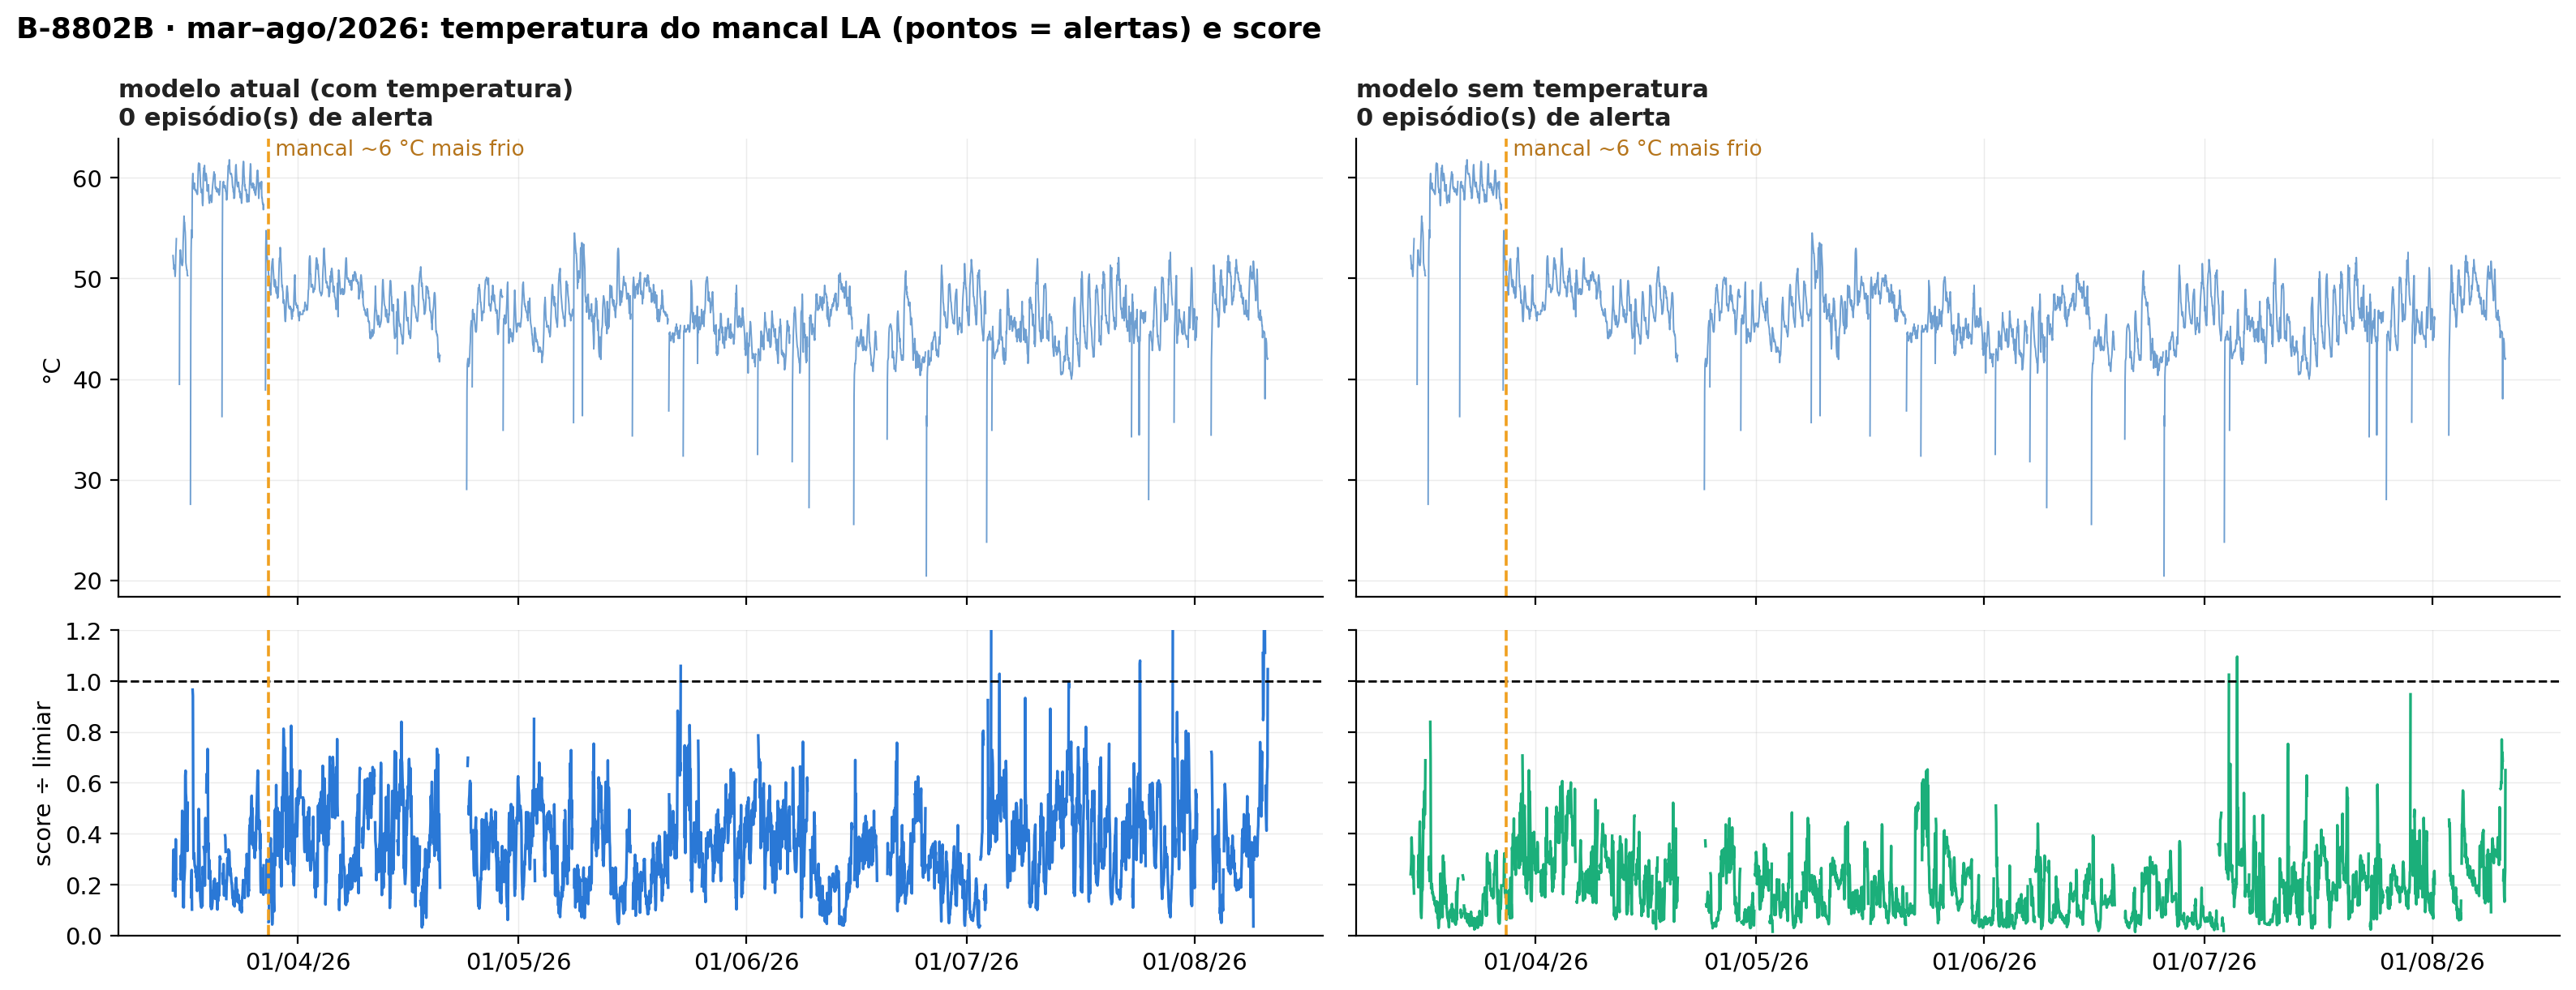

In [6]:
_ = lado_a_lado(raw, "2026-03-15", "2026-08-11", "Temperatura Bomba LA", "°C", "mar–ago/2026: temperatura do mancal LA (pontos = alertas) e score",
                agreg="1h", ylim_score=(0, 1.2), marcas=[("2026-03-28", "mancal ~6 °C mais frio")])

**Leitura:** depois do mancal esfriar, o score do modelo atual sobe e encosta no limiar várias vezes em jul–ago/2026 —
só não vira alerta por causa da persistência (15 de 20 leituras + 1 h). O do modelo sem temperatura fica baixo: para
ele, nada mudou, e de fato nada indica falha nesse período.

## 4. A falha real de 2022

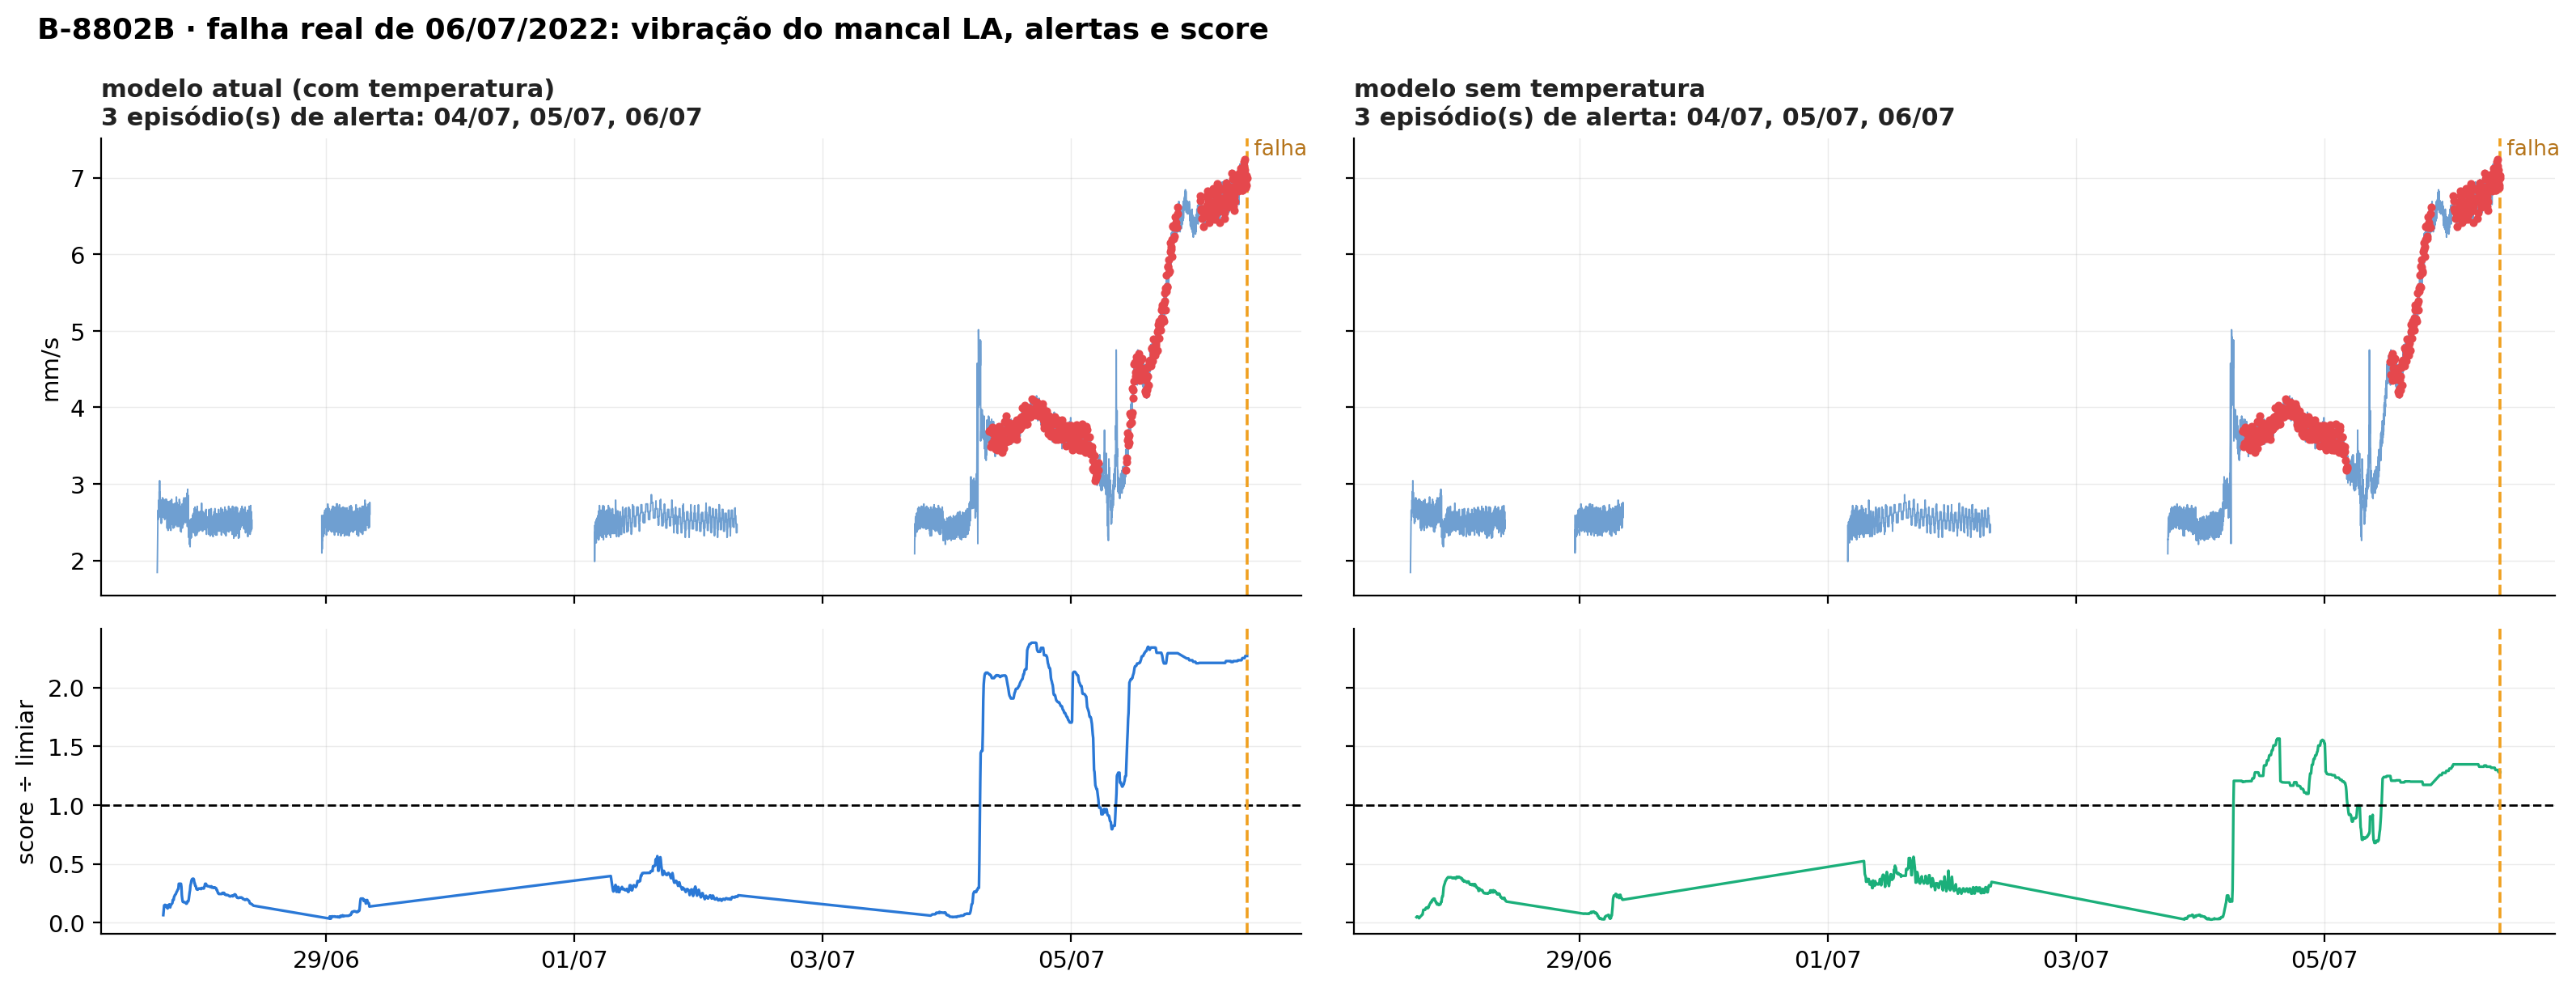

In [7]:
_ = lado_a_lado(raw22, "2022-06-27", FALHA, "Vibração Bomba LA", "mm/s", "falha real de 06/07/2022: vibração do mancal LA, alertas e score",
                marcas=[(FALHA, "falha")])

## 5. A falha simulada de 10/06/2026 (assinatura da falha de 2022 somada ao dado real)

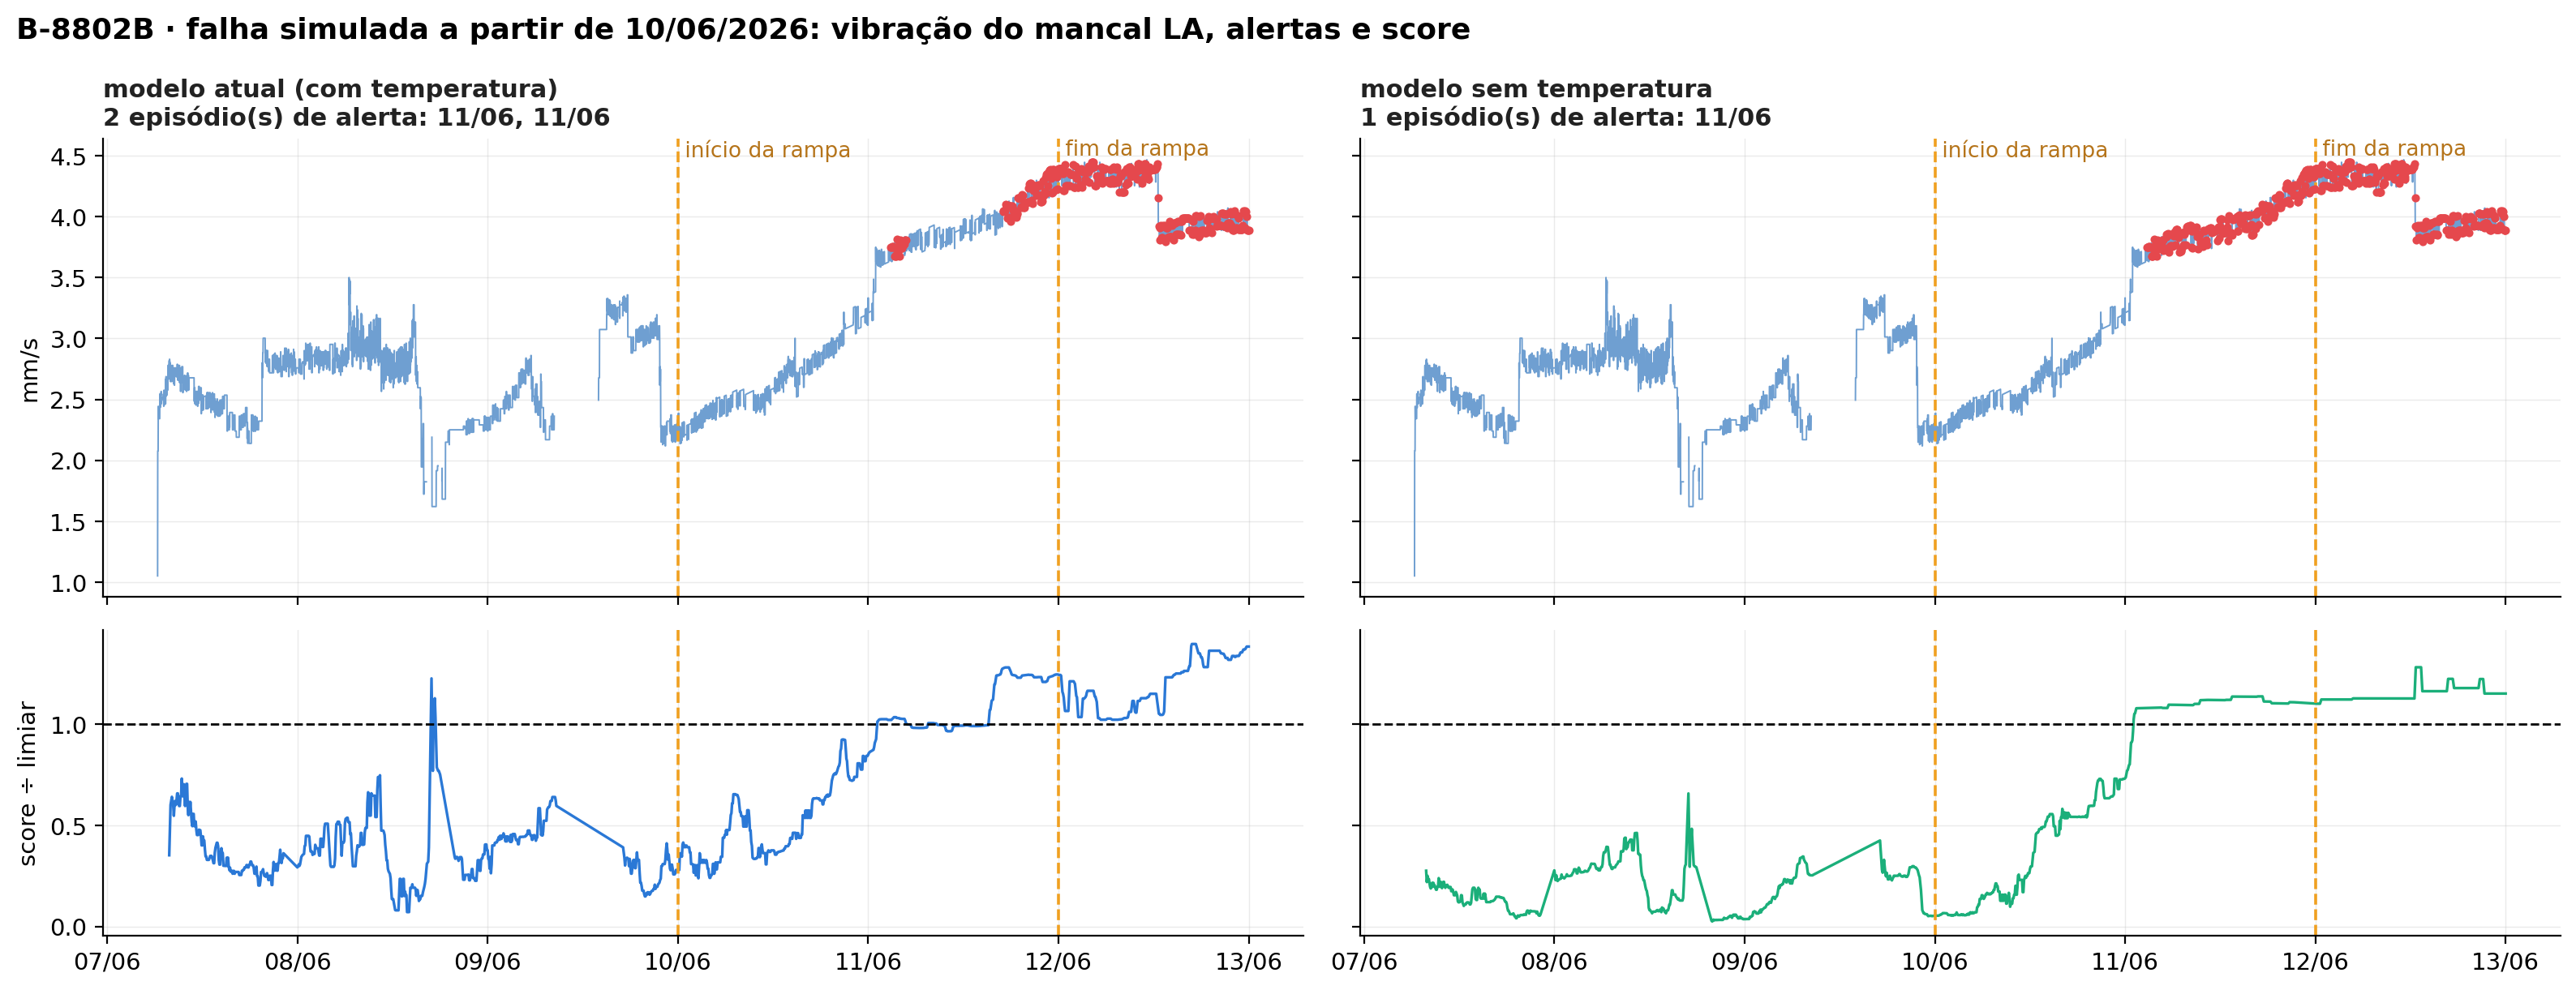

In [8]:
t0 = pd.Timestamp("2026-06-10"); tf = t0 + pd.Timedelta(hours=48)
inj = battery.inject(raw.loc[t0 - pd.Timedelta(days=6): tf + pd.Timedelta(hours=30)], B["synthetic"]["signature"], t0, 48, 24, 1.0)
_ = lado_a_lado(inj, str(t0 - pd.Timedelta(days=3)), str(tf + pd.Timedelta(hours=24)), "Vibração Bomba LA", "mm/s",
                "falha simulada a partir de 10/06/2026: vibração do mancal LA, alertas e score",
                marcas=[(t0, "início da rampa"), (tf, "fim da rampa")])

**Leitura das falhas (seções 4 e 5):** os dois modelos se comportam igual — alertam ao mesmo tempo, porque a falha
está na vibração, que os dois têm.

## 6. Os números lado a lado

In [9]:
def antecedencia(bundle, df, t_fim, ini):
    s, a = rodar(bundle, df); a = a.loc[ini:t_fim]
    return round((t_fim - a[a].index.min()).total_seconds() / 3600) if a.any() else None
tab = {}
for nome, (b, cor) in MODELOS.items():
    s, a = rodar(b, raw)
    col = {"episódios de alerta em 2025": len(episodios(a.loc["2025"])), "episódios de alerta em 2026": len(episodios(a.loc["2026"])),
           "alerta em 10–12/01/26": "sim" if a.loc["2026-01-10":"2026-01-13"].any() else "não",
           "alerta em 17/01/26": "sim" if a.loc["2026-01-17 19:30":"2026-01-18 00:40"].any() else "não",
           "score abr–ago/26 ÷ 2025": round(s.loc["2026-04":"2026-08"].mean() / s.loc["2025"].mean(), 2),
           "falha real 2022 (h antes)": antecedencia(b, raw22, FALHA, "2022-06-29")}
    for d in ["2026-01-25", "2026-06-10", "2026-07-15"]:
        t0 = pd.Timestamp(d); tf = t0 + pd.Timedelta(hours=48)
        inj = battery.inject(raw.loc[t0 - pd.Timedelta(days=5): tf + pd.Timedelta(hours=24)], B["synthetic"]["signature"], t0, 48, 24, 1.0)
        v = antecedencia(b, inj, tf + pd.Timedelta(hours=24), t0)
        col[f"falha simulada {t0:%d/%m} (h antes do fim da rampa)"] = None if v is None else v - 24
    tab[nome] = col
pd.DataFrame(tab)

,modelo atual (com temperatura),modelo sem temperatura
episódios de alerta em 2025,0,0
episódios de alerta em 2026,1,2
alerta em 10–12/01/26,não,sim
alerta em 17/01/26,sim,sim
score abr–ago/26 ÷ 2025,2.12,1.24
falha real 2022 (h antes),50,50
falha simulada 25/01 (h antes do fim da rampa),28,31
falha simulada 10/06 (h antes do fim da rampa),21,21
falha simulada 15/07 (h antes do fim da rampa),7,7
